# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Dự báo mức sẵn sàng ngày kế tiếp từ lifelog Fitbit và nhật ký tập luyện trên PMData với mười mô hình hồi quy và lời giải thích được kiểm tra

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** mọi notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.

In [ ]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost shap matplotlib scipy

In [1]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** dòng cuối in số file tìm thấy. Nếu tải tự động lỗi, tải tay tại `datasets.simula.no/pmdata`, chép vào `data/raw/` rồi chạy lại ô này.

In [2]:
FILES = [('https://datasets.simula.no/downloads/pmdata.zip', 'pmdata.zip')]
MARKER = 'data/raw/**/p[0-9][0-9]/fitbit/steps.json'
if not glob.glob(MARKER, recursive=True):
    for url, name in FILES: fetch(url, name)
    unzip_all()
found = glob.glob(MARKER, recursive=True)
assert found, 'data not found: download by hand from datasets.simula.no/pmdata into data/raw and run this cell again'
print(len(found), 'files found, for example', found[0])

16 files found, for example data/raw\p01\fitbit\steps.json


## Bước 1b. Nạp dữ liệu và trích đặc trưng

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số người, số lớp, số dòng với mô tả của bộ dữ liệu.

In [6]:
# Step 1b: PMData (Thambawita et al., 2020): 16 people, 5 months, Fitbit Versa 2 plus PMSYS wellness and training logs
# download (one zip, no account): https://datasets.simula.no/pmdata/
import pandas as pd, numpy as np, glob, os, json

def jl(path): return pd.json_normalize(json.load(open(path, encoding='utf-8')))            # Fitbit JSON list to flat table

def daily(path, name):                                                   # one value per day
    d = jl(path); d['date'] = pd.to_datetime(d.dateTime).dt.normalize()
    return d.assign(**{name: pd.to_numeric(d['value'], errors='coerce')}).groupby('date')[name].sum().reset_index()

days, hours = [], []
for p in sorted(glob.glob('data/raw/**/p[0-9][0-9]', recursive=True)):
    pid = os.path.basename(p); fb = p + '/fitbit/'
    st = jl(fb + 'steps.json'); st['ts'] = pd.to_datetime(st.dateTime); st['steps'] = pd.to_numeric(st['value'])
    hr = st.groupby(st.ts.dt.floor('h')).steps.sum().reset_index().assign(pid=pid); hours.append(hr)   # hourly table
    d = hr.groupby(hr.ts.dt.normalize()).steps.sum().rename_axis('date').reset_index()
    for f, name in [('very_active_minutes', 'very_active'), ('sedentary_minutes', 'sedentary')]:
        d = d.merge(daily(fb + f + '.json', name), on='date', how='left')
    
    rhr_path = fb + 'resting_heart_rate.json'
    if os.path.exists(rhr_path):
        r = jl(rhr_path); r['date'] = pd.to_datetime(r.dateTime).dt.normalize()
        d = d.merge(r[r['value.value'] > 0][['date', 'value.value']].rename(columns={'value.value': 'rhr'}), on='date', how='left')
    else:
        d['rhr'] = np.nan; print(f'  {pid}: resting_heart_rate.json not found, rhr set to NaN')
        
    s = jl(fb + 'sleep.json'); s = s[s.mainSleep]; s['date'] = pd.to_datetime(s.dateOfSleep)      # night ending that morning
    d = d.merge(s.groupby('date').agg(sleep_min=('minutesAsleep', 'sum'), sleep_eff=('efficiency', 'mean')).reset_index(),
                on='date', how='left')
    w = pd.read_csv(p + '/pmsys/wellness.csv'); w['date'] = pd.to_datetime(w.effective_time_frame).dt.tz_localize(None).dt.normalize()
    d = d.merge(w.groupby('date')[['fatigue', 'mood', 'readiness', 'sleep_quality', 'soreness', 'stress']].mean().reset_index(),
                on='date', how='left')
    t = pd.read_csv(p + '/pmsys/srpe.csv'); t['date'] = pd.to_datetime(t.end_date_time).dt.tz_localize(None).dt.normalize()
    t['load'] = t.perceived_exertion * t.duration_min                    # session load = effort x minutes
    d = d.merge(t.groupby('date').load.sum().reset_index(), on='date', how='left'); days.append(d.assign(pid=pid))

df = pd.concat(days, ignore_index=True); hourly = pd.concat(hours, ignore_index=True)
print(df.shape, hourly.shape, df.pid.nunique(), 'people', int(df.readiness.notna().sum()), 'readiness reports')


  p12: resting_heart_rate.json not found, rhr set to NaN
  p13: resting_heart_rate.json not found, rhr set to NaN
(2178, 15) (46593, 3) 16 people 1668 readiness reports


## Bước 2. Làm sạch có nhật ký

- **Làm gì:** loại dòng lỗi, đặt tên nhãn, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [7]:
# Step 2: plausible ranges, non-wear days, cleaning log
log = [['person-days', len(df)]]
df['load'] = df.load.fillna(0)                                           # no session logged means rest day
df.loc[df.steps < 500, ['steps', 'very_active', 'sedentary']] = np.nan   # watch not worn
df.loc[~df.rhr.between(30, 120), 'rhr'] = np.nan
df.loc[~df.sleep_min.between(120, 900), ['sleep_min', 'sleep_eff']] = np.nan
log.append(['days with readiness report', int(df.readiness.notna().sum())])
log.append(['days with Fitbit steps', int(df.steps.notna().sum())])
df = df.sort_values(['pid', 'date']).drop_duplicates(['pid', 'date'])
pd.DataFrame(log, columns=['step', 'rows']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
df.to_parquet('data/processed/pmdata_daily.parquet', index=False)
hourly.to_parquet('data/processed/pmdata_hourly.parquet', index=False); print(df.isna().mean().round(2))

[['person-days', 2178], ['days with readiness report', 1668], ['days with Fitbit steps', 2107]]
date             0.00
steps            0.03
very_active      0.03
sedentary        0.03
rhr              0.24
sleep_min        0.15
sleep_eff        0.15
fatigue          0.23
mood             0.23
readiness        0.23
sleep_quality    0.23
soreness         0.23
stress           0.23
load             0.00
pid              0.00
dtype: float64


## Bước 3. SQL trả lời RQ1 và tạo bảng mô hình

- **Làm gì:** ghi các truy vấn vào `sql/queries.sql` rồi chạy từng truy vấn bằng DuckDB.
- **Vì sao:** RQ1 được trả lời bằng bảng số; đặc trưng dùng LAG hoặc LEAD chỉ lấy thông tin quá khứ nên không rò rỉ.
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [8]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE d AS SELECT * FROM 'data/processed/pmdata_daily.parquet';
CREATE OR REPLACE TABLE h AS SELECT * FROM 'data/processed/pmdata_hourly.parquet';
-- Q1: reports and typical readiness per person (how different people are from each other)
SELECT pid, COUNT(readiness) AS reports, AVG(readiness) AS readiness, STDDEV(readiness) AS sd, AVG(steps) AS steps,
       AVG(load) AS load FROM d GROUP BY 1 ORDER BY 1;
-- Q2: next-morning readiness after hard, light and rest days (LEAD gives the report of the following day)
WITH n AS (SELECT *, LEAD(readiness) OVER (PARTITION BY pid ORDER BY date) AS next_ready,
                  LEAD(date) OVER (PARTITION BY pid ORDER BY date) AS next_date FROM d)
SELECT CASE WHEN load = 0 THEN 'rest' WHEN load < 400 THEN 'light' ELSE 'hard' END AS day_type, COUNT(*) AS n,
       AVG(next_ready) AS next_readiness, AVG(sleep_min) AS sleep_min
FROM n WHERE next_ready IS NOT NULL AND next_date = date + INTERVAL 1 DAY GROUP BY 1 HAVING COUNT(*) > 20 ORDER BY 3;
-- Q3: hourly step profile, weekday against weekend (hourly table, the large one)
SELECT HOUR(ts) AS hour, CASE WHEN DAYOFWEEK(ts) IN (0, 6) THEN 'weekend' ELSE 'weekday' END AS part, AVG(steps) AS steps
FROM h GROUP BY 1, 2 ORDER BY 1, 2;
-- Q4: model table; target is tomorrow's readiness, every feature is known by tonight (past-only windows)
CREATE OR REPLACE TABLE feat AS
WITH b AS (
  SELECT *, LEAD(readiness) OVER o AS y, LEAD(date) OVER o AS next_date, ROW_NUMBER() OVER o AS day_no,
         AVG(load) OVER (PARTITION BY pid ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW) AS load_7d,
         AVG(load) OVER (PARTITION BY pid ORDER BY date ROWS BETWEEN 27 PRECEDING AND CURRENT ROW) AS load_28d,
         AVG(sleep_min) OVER (PARTITION BY pid ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW) AS sleep_7d,
         AVG(readiness) OVER (PARTITION BY pid ORDER BY date ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS ready_base,
         AVG(rhr) OVER (PARTITION BY pid ORDER BY date ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS rhr_base,
         AVG(steps) OVER (PARTITION BY pid ORDER BY date ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS steps_base
  FROM d WINDOW o AS (PARTITION BY pid ORDER BY date))
SELECT *, load_7d / NULLIF(load_28d, 0) AS load_ratio, readiness - ready_base AS ready_dev, rhr - rhr_base AS rhr_dev,
       steps - steps_base AS steps_dev, DAYOFWEEK(date) AS dow
FROM b WHERE y IS NOT NULL AND readiness IS NOT NULL AND next_date = date + INTERVAL 1 DAY AND day_no > 7;
SELECT COUNT(*) AS rows, COUNT(DISTINCT pid) AS people FROM feat;
"""
open('sql/queries.sql', 'w').write(SQL)

2645

In [9]:
import duckdb, pandas as pd
def statements(sql):                      # split on the semicolon that ends a code line, comments may contain semicolons
    out, cur = [], []
    for line in sql.split('\n'):
        cur.append(line)
        if line.split('--')[0].rstrip().endswith(';'): out.append('\n'.join(cur).strip()); cur = []
    return out
con = duckdb.connect(); n = 0
for stmt in statements(SQL):
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if body.upper().startswith(('SELECT', 'WITH')):
        n += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % n, index=False)
        print(stmt.split('\n')[0]); display(r.head(15))
    else: con.execute(stmt)

-- Q1: reports and typical readiness per person (how different people are from each other)


,pid,reports,readiness,sd,steps,load
0,p01,138,6.224638,1.414307,12622.881579,62.565789
1,p02,98,4.765306,1.282724,16137.541096,198.851351
2,p03,66,5.000000,0.175412,6440.584158,2.950820
3,p04,139,5.194245,1.041722,10525.784722,159.523810
4,p05,128,2.781250,2.490731,11546.781690,11.527778
5,p06,147,4.789116,1.732965,13960.655629,55.065789
6,p07,132,3.643939,1.230233,15791.727891,249.183673
7,p08,100,4.815000,1.814163,16212.525180,324.964029
8,p09,101,4.712871,0.993344,6393.800000,8.344371
9,p10,94,3.404255,1.401375,11976.646018,60.964912


-- Q2: next-morning readiness after hard, light and rest days (LEAD gives the report of the following day)


,day_type,n,next_readiness,sleep_min
0,light,381,4.833771,433.387931
1,rest,1066,4.924484,404.199561
2,hard,201,5.238806,436.877005


-- Q3: hourly step profile, weekday against weekend (hourly table, the large one)


,hour,part,steps
0,0,weekday,62.917981
1,0,weekend,165.562016
2,1,weekday,46.896497
3,1,weekend,120.259481
4,2,weekday,45.177407
5,2,weekend,69.876248
6,3,weekday,34.052133
7,3,weekend,39.840319
8,4,weekday,56.526395
9,4,weekend,41.163743


SELECT COUNT(*) AS rows, COUNT(DISTINCT pid) AS people FROM feat;


,rows,people
0,1324,16


## Bước 5. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

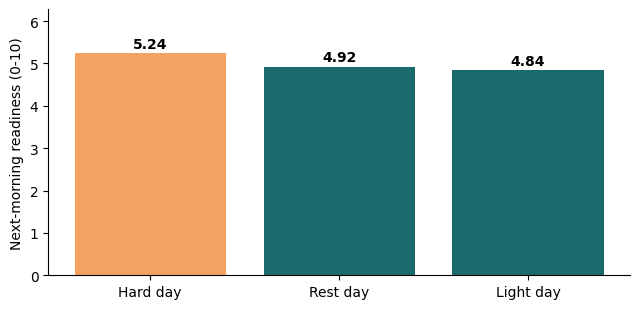

In [10]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30)
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""WITH n AS (SELECT *, LEAD(readiness) OVER (PARTITION BY pid ORDER BY date) AS nr FROM d) SELECT CASE WHEN load = 0 THEN 'Rest day' WHEN load < 400 THEN 'Light day' ELSE 'Hard day' END AS g, AVG(nr) AS v FROM n WHERE nr IS NOT NULL GROUP BY 1 ORDER BY 2 DESC""").df()
bar_chart(fig1.g, fig1.v, 'Next-morning readiness (0-10)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [11]:
import json, hashlib
path = 'data/processed/pmdata_daily.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert not t.duplicated().any(), 'duplicated rows'
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/pmdata_daily.parquet', 'rows': 2178, 'columns': 15, 'feat_rows': 1324, 'md5': '38307edd8318e4c65d195b9c2c1865ba'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước 12:00 ngày báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: